# Partie 1 — Chargement et prétraitement des données

In [6]:
%pip install kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 KB 6.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 KB 4.4 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [7]:
from pathlib import Path
import pandas as pd
import numpy as np
import time
import gc
import tensorflow as tf
import keras
from keras import layers
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from keras.applications import MobileNetV2
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import shuffle
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score, roc_auc_score, classification_report

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
path = Path(path)

train_directory = path / "chest_xray" / "chest_xray" / "train"
val_directory = path / "chest_xray" / "chest_xray" / "val"
test_directory = path / "chest_xray" / "chest_xray" / "test"

IMAGE_SIZE = (180, 180)
BATCH_SIZE = 8
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".png", ".bmp", ".gif"}

 20%|█▉        | 466M/2.29G [04:27<18:01, 1.83MB/s] 


KeyboardInterrupt: 

In [ ]:
def make_dataset(directory, shuffle_data=False):
    image_paths = []
    labels = []

    for label, class_name in enumerate(("NORMAL", "PNEUMONIA")):
        class_directory = Path(directory) / class_name

        class_paths = sorted(
            str(file_path)
            for file_path in class_directory.iterdir()
            if file_path.is_file()
            and file_path.suffix.lower() in IMAGE_EXTENSIONS
        )

        image_paths.extend(class_paths)
        labels.extend([label] * len(class_paths))

    dataset = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if shuffle_data:
        dataset = dataset.shuffle(
            len(image_paths),
            seed=42
        )

    def decode_and_resize(image_path, label):
        image_bytes = tf.io.read_file(image_path)

        image = tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32) / 255.0
        label = tf.reshape(
            tf.cast(label, tf.float32),
            (1,)
        )

        return image, label

    return (
        dataset
        .map(
            decode_and_resize,
            num_parallel_calls=tf.data.AUTOTUNE
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

train_ds = make_dataset(train_directory, shuffle_data=True)
val_ds = make_dataset(val_directory)
test_ds = make_dataset(test_directory)

I0000 00:00:1792670660.516299    1078 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 44142 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:05:00.0, compute capability: 7.5


### Vérification des images et des fichiers invalides

In [ ]:
def check_image(img_path):
    try:
        image_bytes = tf.io.read_file(str(img_path))
        tf.io.decode_image(
            image_bytes,
            channels=3,
            expand_animations=False
        )
        return True
    except Exception:
        return False

def get_images(directory):
    return [
        file_path
        for file_path in Path(directory).rglob("*")
        if file_path.is_file()
        and file_path.suffix.lower() in IMAGE_EXTENSIONS
    ]

for name, directory in [
    ("TRAIN", train_directory),
    ("VALIDATION", val_directory),
    ("TEST", test_directory)
]:
    images = get_images(directory)
    invalid = [img for img in images if not check_image(img)]

    print(f"{name}: {len(images)} images")
    print(f"{name}: {len(invalid)} images invalides")

TRAIN: 5216 images
TRAIN: 0 images invalides
VALIDATION: 16 images
VALIDATION: 0 images invalides
TEST: 624 images
TEST: 0 images invalides


### Visualisation et répartition des classes

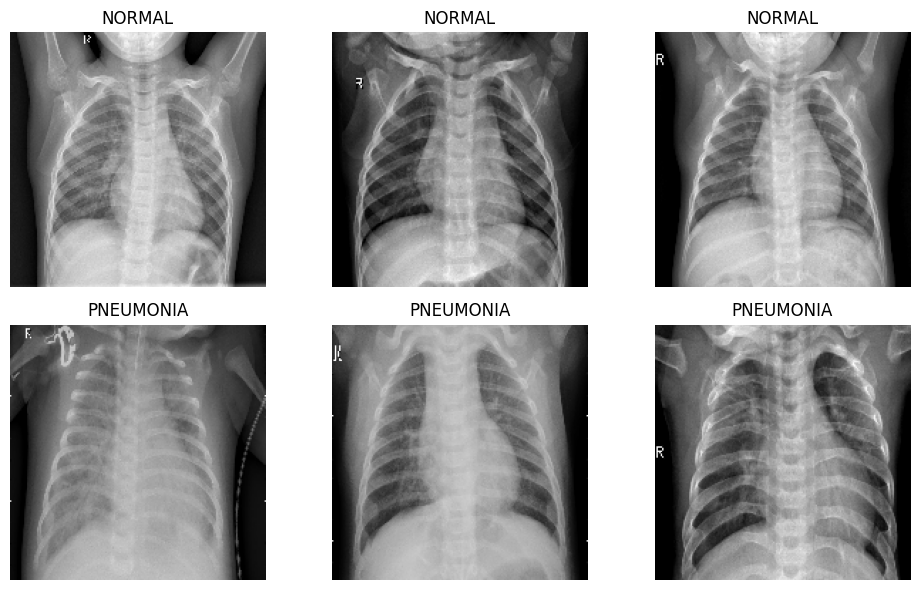

In [ ]:
def show_images(directory, n=3):
    fig, axes = plt.subplots(2, n, figsize=(10, 6))

    for row, class_name in enumerate(("NORMAL", "PNEUMONIA")):
        class_dir = Path(directory) / class_name

        files = [
            f for f in sorted(class_dir.iterdir())
            if f.is_file()
            and f.suffix.lower() in IMAGE_EXTENSIONS
            and check_image(f)
        ][:n]

        for col in range(n):
            axes[row, col].axis("off")

            if col < len(files):
                image = keras.utils.load_img(
                    files[col],
                    target_size=IMAGE_SIZE
                )
                axes[row, col].imshow(image)
                axes[row, col].set_title(class_name)

    plt.tight_layout()
    plt.show()

show_images(train_directory)

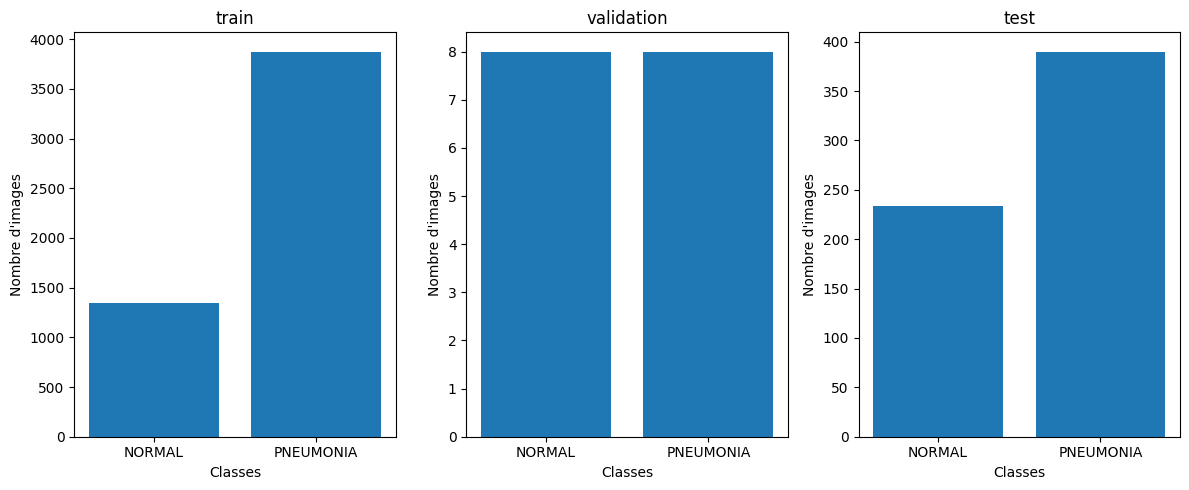

In [ ]:
def count_images(directory):
    return [
        len([
            f for f in (Path(directory) / class_name).iterdir()
            if f.is_file()
            and f.suffix.lower() in IMAGE_EXTENSIONS
        ])
        for class_name in ("NORMAL", "PNEUMONIA")
    ]

counts = {
    "train": count_images(train_directory),
    "validation": count_images(val_directory),
    "test": count_images(test_directory)
}

classes = ("NORMAL", "PNEUMONIA")

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

for i, (key, values) in enumerate(counts.items()):
    axes[i].bar(classes, values)
    axes[i].set_title(key)
    axes[i].set_xlabel("Classes")
    axes[i].set_ylabel("Nombre d'images")

plt.tight_layout()
plt.show()

### Conversion manuelle des images en tableaux NumPy

In [ ]:
def process_image(img):
    image_bytes = tf.io.read_file(str(img))

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0

    return image.numpy().astype(np.float32)

In [ ]:
train_image = {
    "normal": get_images(train_directory / "NORMAL"),
    "pneumonia": get_images(train_directory / "PNEUMONIA")
}

val_image = {
    "normal": get_images(val_directory / "NORMAL"),
    "pneumonia": get_images(val_directory / "PNEUMONIA")
}

test_image = {
    "normal": get_images(test_directory / "NORMAL"),
    "pneumonia": get_images(test_directory / "PNEUMONIA")
}

train_valid = {
    cls: [img for img in train_image[cls] if check_image(img)]
    for cls in ["normal", "pneumonia"]
}

val_valid = {
    cls: [img for img in val_image[cls] if check_image(img)]
    for cls in ["normal", "pneumonia"]
}

test_valid = {
    cls: [img for img in test_image[cls] if check_image(img)]
    for cls in ["normal", "pneumonia"]
}

In [ ]:
train_processed = {
    cls: np.array([
        process_image(img)
        for img in train_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

val_processed = {
    cls: np.array([
        process_image(img)
        for img in val_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

test_processed = {
    cls: np.array([
        process_image(img)
        for img in test_valid[cls]
    ])
    for cls in ["normal", "pneumonia"]
}

In [ ]:
X_train = np.concatenate(
    (
        train_processed["normal"],
        train_processed["pneumonia"]
    ),
    axis=0
)

y_train = np.concatenate(
    (
        np.zeros(len(train_processed["normal"])),
        np.ones(len(train_processed["pneumonia"]))
    ),
    axis=0
)

X_val = np.concatenate(
    (
        val_processed["normal"],
        val_processed["pneumonia"]
    ),
    axis=0
)

y_val = np.concatenate(
    (
        np.zeros(len(val_processed["normal"])),
        np.ones(len(val_processed["pneumonia"]))
    ),
    axis=0
)

X_test = np.concatenate(
    (
        test_processed["normal"],
        test_processed["pneumonia"]
    ),
    axis=0
)

y_test = np.concatenate(
    (
        np.zeros(len(test_processed["normal"])),
        np.ones(len(test_processed["pneumonia"]))
    ),
    axis=0
)

X_train, y_train = shuffle(
    X_train,
    y_train,
    random_state=42
)

X_train = np.asarray(X_train, dtype=np.float32)
y_train = np.asarray(y_train, dtype=np.float32)

# Partie 2 — Conception du modèle CNN

In [ ]:
def equilbre():
    classes = np.unique(y_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )

    class_weights = {
        int(cls): float(weight)
        for cls, weight in zip(classes, weights)
    }

    print(class_weights)

    return class_weights


class_weights = equilbre()

model = keras.Sequential([
    keras.Input(shape=(180, 180, 3)),
    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc")
    ]
)

model.summary()

{0: 1.9448173005219984, 1: 0.6730322580645162}


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 118336)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    15,147,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,166,657 (57.86 MB)

 Trainable params: 15,166,657 (57.86 MB)

 Non-trainable params: 0 (0.00 B)

# Partie 3 — Entraînement et optimisation du CNN

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "best_pneumonia_model.keras",
    monitor="val_loss",
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.1,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

start = time.time()

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint]
)

end = time.time()
training_duration = end - start
cnn_model = model

print(f"Temps d'entraînement : {training_duration:.2f} secondes")

Epoch 1/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.8463 - auc: 0.9006 - loss: 0.4853 - precision: 0.9356 - recall: 0.8543 - val_accuracy: 0.8750 - val_auc: 0.9531 - val_loss: 0.2411 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9385 - auc: 0.9827 - loss: 0.1655 - precision: 0.9778 - recall: 0.9376 - val_accuracy: 1.0000 - val_auc: 1.0000 - val_loss: 0.0873 - val_precision: 1.0000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.9664 - auc: 0.9919 - loss: 0.1054 - precision: 0.9890 - recall: 0.9651 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1718 - val_precision: 0.8889 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 4/5
651/652 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9752 - auc: 0.9959 - loss: 0.0760 - precision: 0.9927 - recall: 0.9732
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.000100000004

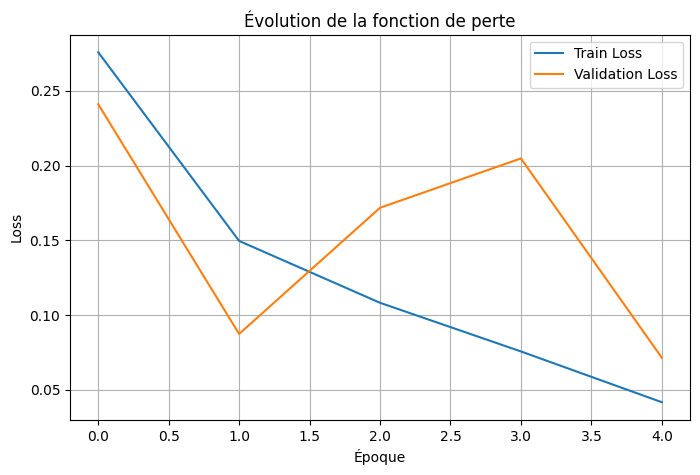

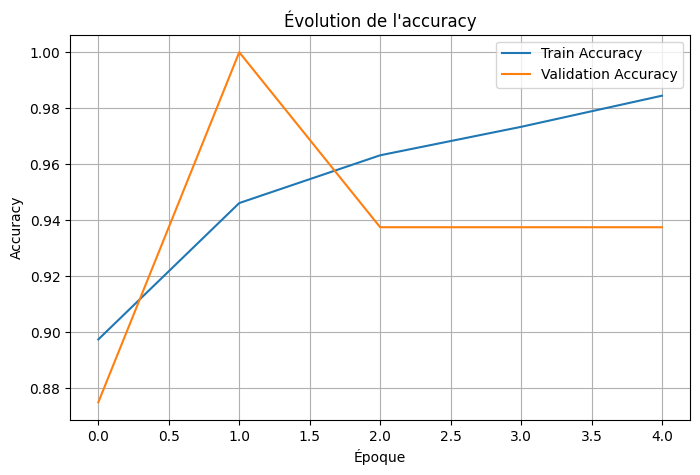

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.title("Évolution de la fonction de perte")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.title("Évolution de l'accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Partie 4 — Évaluation du CNN

In [ ]:
probabilities = model.predict(
    X_test,
    verbose=0
).ravel()

y_pred = (probabilities >= 0.5).astype(int)

scores = model.evaluate(
    X_test,
    y_test,
    return_dict=True
)

print(scores)
print("F1-score :", f1_score(y_test, y_pred))
print(
    "ROC-AUC :",
    roc_auc_score(y_test, probabilities)
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    )
)

20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.5207 - auc: 0.5585 - loss: 2.3391 - precision: 0.3552 - recall: 0.6636       
{'accuracy': 0.7435897588729858, 'auc': 0.8344016671180725, 'loss': 1.2848867177963257, 'precision': 0.7106227278709412, 'recall': 0.9948717951774597}
F1-score : 0.8290598290598291
ROC-AUC : 0.9158612754766601
              precision    recall  f1-score   support

      NORMAL       0.97      0.32      0.49       234
   PNEUMONIA       0.71      0.99      0.83       390

    accuracy                           0.74       624
   macro avg       0.84      0.66      0.66       624
weighted avg       0.81      0.74      0.70       624



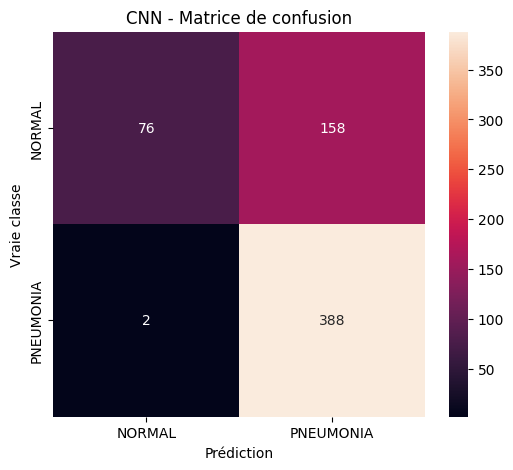

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)
plt.xlabel("Prédiction")
plt.ylabel("Vraie classe")
plt.title("CNN - Matrice de confusion")
plt.show()

In [ ]:
image = X_test[0]
true_label = y_test[0]

image_batch = np.expand_dims(
    image,
    axis=0
)

probability = model.predict(
    image_batch,
    verbose=0
)[0][0]

predicted_class = (
    "PNEUMONIA"
    if probability >= 0.5
    else "NORMAL"
)

print("True label :", true_label)
print("Probabilité PNEUMONIA :", probability)
print("Classe prédite :", predicted_class)

True label : 0.0
Probabilité PNEUMONIA : 0.37139413
Classe prédite : NORMAL


# Partie 5 — Data Augmentation et Transfer Learning

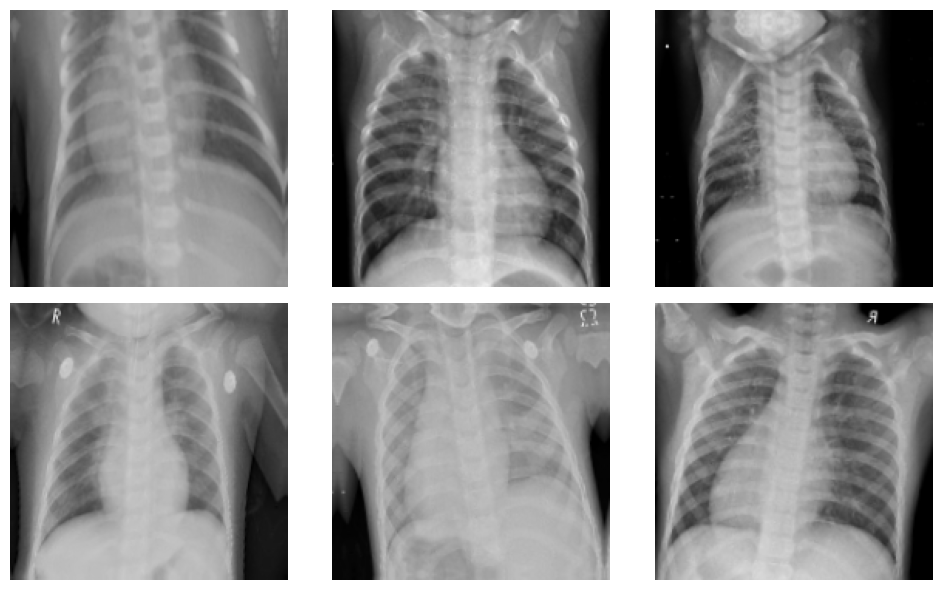

2026-10-22 12:20:27.276534: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
])

for images, labels in train_ds.take(1):
    augmented_images = data_augmentation(images)

    plt.figure(figsize=(10, 6))

    for i in range(min(6, len(augmented_images))):
        plt.subplot(2, 3, i + 1)
        plt.imshow(augmented_images[i])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
base_model_tl = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

base_model_tl.trainable = False

tl_model = keras.Sequential([
    layers.Input((None, None, 3)),
    layers.Resizing(180, 180),
    layers.Rescaling(
        scale=2.0,
        offset=-1.0
    ),
    base_model_tl,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

tl_model.summary()

/tmp/ipykernel_1078/698310023.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_tl = MobileNetV2(


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Partie 6 — Entraînement du Transfer Learning

In [ ]:
def train_model_save(
    model,
    name,
    eta=1e-3,
    save=False,
    dataset=train_ds,
    validation_dataset=val_ds
):
    model.compile(
        optimizer=keras.optimizers.Adam(eta),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )

    history = model.fit(
        dataset,
        epochs=5,
        class_weight=class_weights,
        validation_data=validation_dataset,
        callbacks=[
            early_stopping,
            reduce_lr,
            checkpoint
        ]
    )

    if save:
        model.save(name)

    return history

tl_history = train_model_save(
    tl_model,
    "tl_model.keras",
    eta=1e-3,
    save=True
)

Epoch 1/5


2026-10-22 12:20:39.156670: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-22 12:20:39.300035: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


652/652 ━━━━━━━━━━━━━━━━━━━━ 24s 18ms/step - accuracy: 0.8692 - auc: 0.9233 - loss: 0.3071 - precision: 0.9496 - recall: 0.8743 - val_accuracy: 0.9375 - val_auc: 0.9688 - val_loss: 0.2218 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9503 - auc: 0.9899 - loss: 0.1244 - precision: 0.9867 - recall: 0.9446 - val_accuracy: 0.8750 - val_auc: 0.9844 - val_loss: 0.2589 - val_precision: 0.8000 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 3/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9584 - auc: 0.9923 - loss: 0.1040 - precision: 0.9923 - recall: 0.9517 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1480 - val_precision: 1.0000 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 4/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.9648 - auc: 0.9945 - loss: 0.0895 - precision: 0.9935 - recall: 0.9586 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1339 - val_precisio

# Partie 7 — Fine-tuning progressif

In [ ]:
tf.keras.backend.clear_session()
gc.collect()

ft_base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(180, 180, 3)
)

ft_base_model.trainable = True

for layer in ft_base_model.layers[:-30]:
    layer.trainable = False

ft_model = keras.Sequential([
    layers.Input((None, None, 3)),
    layers.Resizing(180, 180),
    layers.Rescaling(
        scale=2.0,
        offset=-1.0
    ),
    ft_base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

ft_history = train_model_save(
    ft_model,
    "ft_model.keras",
    eta=1e-7,
    save=True
)

/tmp/ipykernel_1078/2174765181.py:4: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  ft_base_model = MobileNetV2(


Epoch 1/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 35s 22ms/step - accuracy: 0.5124 - auc: 0.4654 - loss: 0.7814 - precision: 0.7148 - recall: 0.5588 - val_accuracy: 0.5000 - val_auc: 0.5938 - val_loss: 0.6926 - val_precision: 0.5000 - val_recall: 0.5000 - learning_rate: 1.0000e-07
Epoch 2/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.5660 - auc: 0.5616 - loss: 0.7217 - precision: 0.7664 - recall: 0.5891 - val_accuracy: 0.6250 - val_auc: 0.7812 - val_loss: 0.5887 - val_precision: 0.6667 - val_recall: 0.5000 - learning_rate: 1.0000e-07
Epoch 3/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.5937 - auc: 0.6156 - loss: 0.6845 - precision: 0.7938 - recall: 0.6061 - val_accuracy: 0.8125 - val_auc: 0.8828 - val_loss: 0.5365 - val_precision: 0.8571 - val_recall: 0.7500 - learning_rate: 1.0000e-07
Epoch 4/5
652/652 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.6263 - auc: 0.6827 - loss: 0.6292 - precision: 0.8455 - recall: 0.6180 - val_accuracy: 0.8750 - val_auc: 0.9062 - val_loss

### Vérification des couches dégelées

In [ ]:
for i, layer in enumerate(ft_base_model.layers[-30:]):
    print(i, layer.name, layer.trainable)

0 block_13_project_BN True
1 block_14_expand True
2 block_14_expand_BN True
3 block_14_expand_relu True
4 block_14_depthwise True
5 block_14_depthwise_BN True
6 block_14_depthwise_relu True
7 block_14_project True
8 block_14_project_BN True
9 block_14_add True
10 block_15_expand True
11 block_15_expand_BN True
12 block_15_expand_relu True
13 block_15_depthwise True
14 block_15_depthwise_BN True
15 block_15_depthwise_relu True
16 block_15_project True
17 block_15_project_BN True
18 block_15_add True
19 block_16_expand True
20 block_16_expand_BN True
21 block_16_expand_relu True
22 block_16_depthwise True
23 block_16_depthwise_BN True
24 block_16_depthwise_relu True
25 block_16_project True
26 block_16_project_BN True
27 Conv_1 True
28 Conv_1_bn True
29 out_relu True


# Partie 8 — Évaluation et comparaison des modèles

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss
)

def metrics(y_true, y_pred, y_prob):
    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    loss = log_loss(
        y_true,
        y_prob
    )

    return (
        accuracy,
        loss,
        recall,
        precision,
        auc,
        f1
    )
# CNN
cnn_prob = model.predict(
    test_ds,
    verbose=0
).ravel()

cnn_pred = (cnn_prob >= 0.5).astype(int)

cnn_accuracy, cnn_loss, cnn_recall, cnn_precision, cnn_auc, cnn_f1 = metrics(
    y_test_ds,
    cnn_pred,
    cnn_prob
)


# Transfer Learning
tl_prob = tl_model.predict(
    test_ds,
    verbose=0
).ravel()

tl_pred = (tl_prob >= 0.5).astype(int)

tl_accuracy, tl_loss, tl_recall, tl_precision, tl_auc, tl_f1 = metrics(
    y_test_ds,
    tl_pred,
    tl_prob
)


# Fine-Tuning
ft_prob = ft_model.predict(
    test_ds,
    verbose=0
).ravel()

ft_pred = (ft_prob >= 0.5).astype(int)

ft_accuracy, ft_loss, ft_recall, ft_precision, ft_auc, ft_f1 = metrics(
    y_test_ds,
    ft_pred,
    ft_prob
)

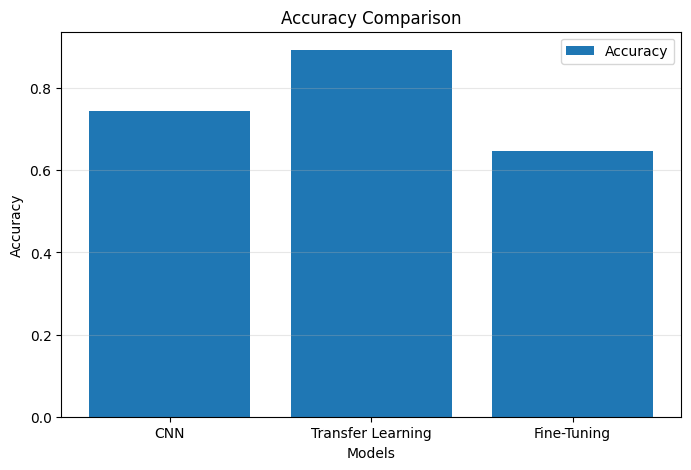

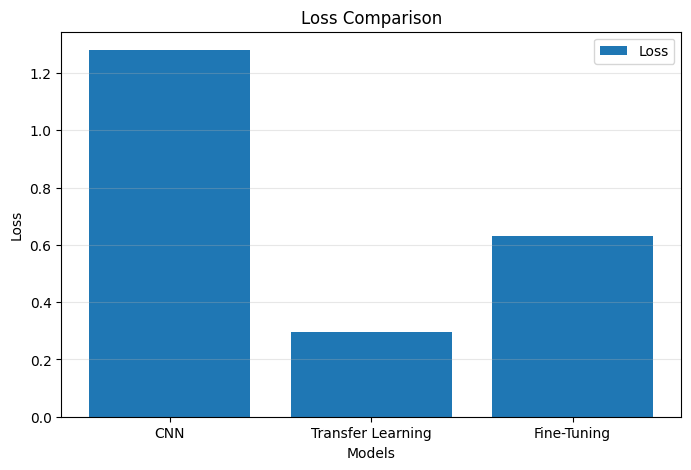

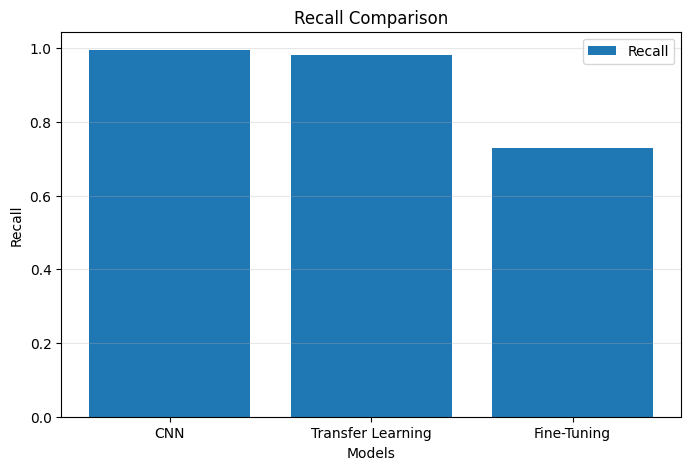

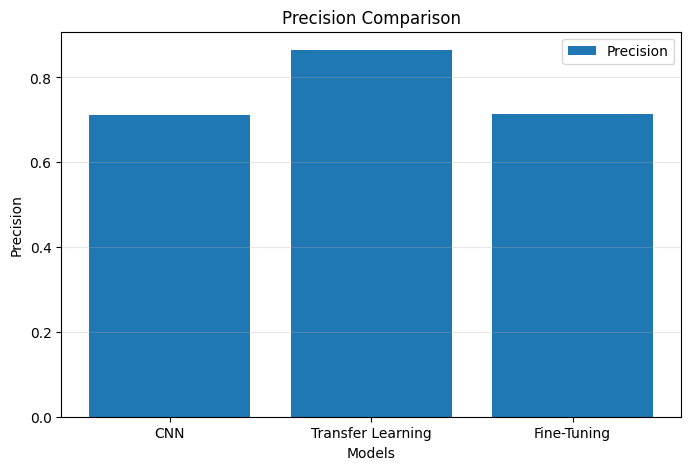

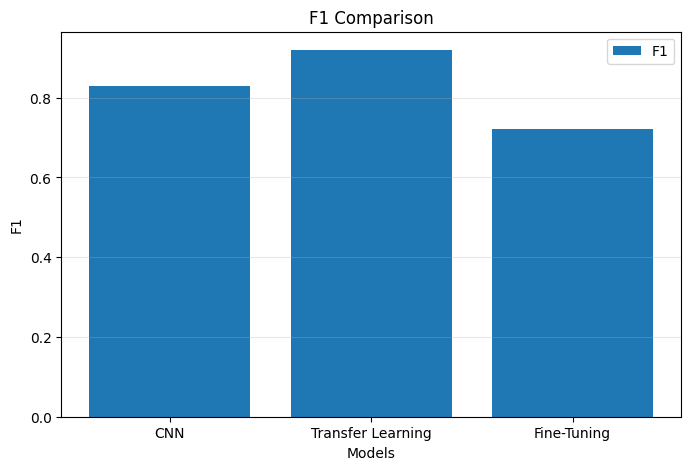

In [ ]:
def plot_metrics(
    cnn_metric,
    tl_metric,
    ft_metric,
    metric_name,
    bar_title
):
    models = [
        "CNN",
        "Transfer Learning",
        "Fine-Tuning"
    ]

    values = [
        cnn_metric,
        tl_metric,
        ft_metric
    ]

    plt.figure(figsize=(8, 5))
    plt.bar(
        models,
        values,
        label=metric_name
    )

    plt.title(bar_title)
    plt.xlabel("Models")
    plt.ylabel(metric_name)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.show()

plot_metrics(
    cnn_accuracy,
    tl_accuracy,
    ft_accuracy,
    "Accuracy",
    "Accuracy Comparison"
)

plot_metrics(
    cnn_loss,
    tl_loss,
    ft_loss,
    "Loss",
    "Loss Comparison"
)

plot_metrics(
    cnn_recall,
    tl_recall,
    ft_recall,
    "Recall",
    "Recall Comparison"
)

plot_metrics(
    cnn_precision,
    tl_precision,
    ft_precision,
    "Precision",
    "Precision Comparison"
)

plot_metrics(
    cnn_f1,
    tl_f1,
    ft_f1,
    "F1",
    "F1 Comparison"
)

In [ ]:
print("CNN Model Metrics:")
print(
    f"Accuracy: {cnn_accuracy:.4f}, "
    f"Loss: {cnn_loss:.4f}, "
    f"Recall: {cnn_recall:.4f}, "
    f"Precision: {cnn_precision:.4f}, "
    f"AUC: {cnn_auc:.4f}, "
    f"F1: {cnn_f1:.4f}"
)

print("TL Model Metrics:")
print(
    f"Accuracy: {tl_accuracy:.4f}, "
    f"Loss: {tl_loss:.4f}, "
    f"Recall: {tl_recall:.4f}, "
    f"Precision: {tl_precision:.4f}, "
    f"AUC: {tl_auc:.4f}, "
    f"F1: {tl_f1:.4f}"
)

print("FT Model Metrics:")
print(
    f"Accuracy: {ft_accuracy:.4f}, "
    f"Loss: {ft_loss:.4f}, "
    f"Recall: {ft_recall:.4f}, "
    f"Precision: {ft_precision:.4f}, "
    f"AUC: {ft_auc:.4f}, "
    f"F1: {ft_f1:.4f}"
)

CNN Model Metrics:
Accuracy: 0.7436, Loss: 1.2803, Recall: 0.9949, Precision: 0.7106, AUC: 0.9159, F1: 0.8291
TL Model Metrics:
Accuracy: 0.8926, Loss: 0.2951, Recall: 0.9821, Precision: 0.8646, AUC: 0.9670, F1: 0.9196
FT Model Metrics:
Accuracy: 0.6474, Loss: 0.6317, Recall: 0.7282, Precision: 0.7136, AUC: 0.6667, F1: 0.7208


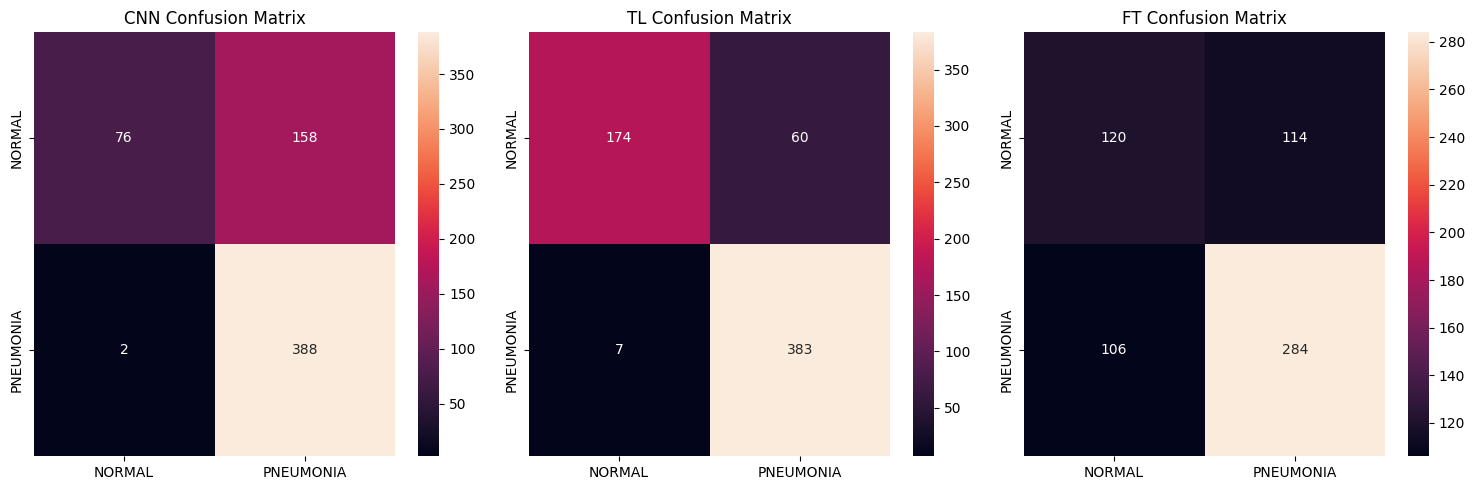

In [ ]:
cnn_cm = confusion_matrix(
    y_test_ds,
    predict_xray(cnn_model)
)

tl_cm = confusion_matrix(
    y_test_ds,
    predict_xray(tl_model)
)

ft_cm = confusion_matrix(
    y_test_ds,
    predict_xray(ft_model)
)

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5)
)

for ax, cm, title in [
    (axes[0], cnn_cm, "CNN Confusion Matrix"),
    (axes[1], tl_cm, "TL Confusion Matrix"),
    (axes[2], ft_cm, "FT Confusion Matrix")
]:
    ax.set_title(title)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["NORMAL", "PNEUMONIA"],
        yticklabels=["NORMAL", "PNEUMONIA"],
        ax=ax
    )

plt.tight_layout()
plt.show()

### Analyse du seuil de décision


In [ ]:
def threshold_analysis(y_true, y_prob):
    rows = []
    for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
        y_pred = (y_prob >= threshold).astype(int)
        rows.append({
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1-score": f1_score(y_true, y_pred, zero_division=0)
        })
    return pd.DataFrame(rows)

ft_probabilities = ft_model.predict(test_ds, verbose=0).ravel()
thresholds = threshold_analysis(y_test_ds, ft_probabilities)
thresholds


,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.642628,0.642249,0.966667,0.771750
1,0.4,0.641026,0.661479,0.871795,0.752212
2,0.5,0.647436,0.713568,0.728205,0.720812
3,0.6,0.583333,0.764228,0.482051,0.591195
4,0.7,0.490385,0.810345,0.241026,0.371542


### Courbe ROC


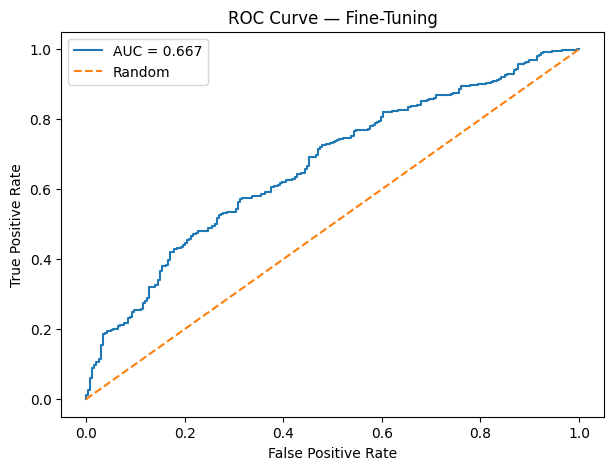

In [ ]:
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test_ds, ft_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test_ds, ft_probabilities):.3f}")
plt.plot([0, 1], [0, 1], "--", label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Fine-Tuning")
plt.legend()
plt.show()


# Partie 9 — Sauvegarde et prédiction

In [ ]:
model = ft_model
MODEL_PATH = "chestscan_final.keras"

model.save(MODEL_PATH)

print("Modèle sauvegardé :", MODEL_PATH)

Modèle sauvegardé : chestscan_final.keras


In [ ]:
def predict_one_image(model, image_path):
    image = keras.utils.load_img(
        image_path,
        target_size=IMAGE_SIZE
    )

    image_array = keras.utils.img_to_array(image)
    image_array = image_array / 255.0
    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    probability = float(
        model.predict(
            image_array,
            verbose=0
        )[0][0]
    )

    predicted_class = (
        "PNEUMONIA"
        if probability >= 0.5
        else "NORMAL"
    )

    print("Classe :", predicted_class)
    print(
        f"Probabilité PNEUMONIA : "
        f"{probability:.2%}"
    )

    return predicted_class, probability



### Analyse des erreurs

2026-10-22 14:02:30.311812: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Nombre d'erreurs : 220


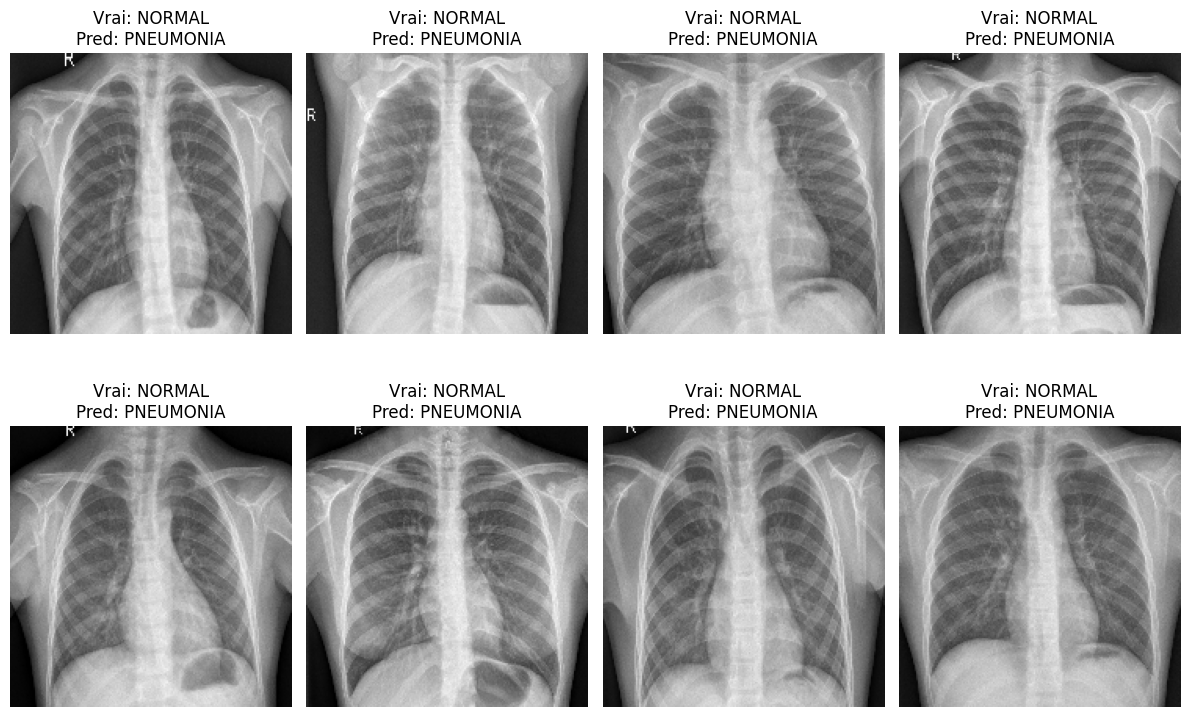

In [ ]:
def show_misclassified(model, dataset, n=8):
    y_true = np.concatenate([
        labels.numpy().ravel()
        for _, labels in dataset
    ]).astype(int)

    y_prob = model.predict(
        dataset,
        verbose=0
    ).ravel()

    y_pred = (y_prob >= 0.5).astype(int)

    wrong = np.where(
        y_true != y_pred
    )[0]

    print("Nombre d'erreurs :", len(wrong))

    if len(wrong) == 0:
        return

    images = np.concatenate([
        images.numpy()
        for images, _ in dataset
    ])

    plt.figure(figsize=(12, 8))

    for i, index in enumerate(wrong[:n]):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[index])
        plt.title(
            f"Vrai: {['NORMAL', 'PNEUMONIA'][y_true[index]]}\n"
            f"Pred: {['NORMAL', 'PNEUMONIA'][y_pred[index]]}"
        )
        plt.axis("off")

    plt.tight_layout()
    plt.show()

show_misclassified(
    ft_model,
    test_ds
)